# Validation croisée et hyperparamètres : tous les modèles du cours

*Introduction au Machine Learning, CNFSDP 2026-2027, Rois Céti DIMBAMBA*

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rdimbamba/ml-cnfsdp/blob/main/notebooks/Validation_croisee.ipynb)

Ce notebook reprend **chaque modèle vu au cours** et répond à trois questions :

1. quels sont **tous ses hyperparamètres**, et lesquels faut-il choisir par validation croisée ;
2. **quelle méthode Python** (classe ou fonction de scikit-learn) fait cette validation croisée ;
3. **un exemple** qui tourne, sur les données des TP (`diabetes` pour la régression, `breast_cancer` pour la classification).

Il se termine par la **consolidation k-means après CAH** : un k-means qui part des centres des classes d'une classification ascendante hiérarchique.

| partie | contenu |
|---|---|
| 1 | Rappels : paramètre, hyperparamètre, validation croisée, les outils de scikit-learn |
| 2 | Régression : polynomiale, moindres carrés, Ridge, Lasso, arbre, forêt, gradient boosting |
| 3 | Classification : référence, k plus proches voisins, logistique, arbre, bagging, forêt, AdaBoost, gradient boosting, seuil de décision |
| 4 | Non supervisé : ACP, k-means, CAH, forêt d'isolement |
| 5 | Récapitulatif |
| 6 | Consolidation k-means après CAH |

## 1. Rappels

**Paramètre et hyperparamètre.** Les *paramètres* sont appris sur les données par `fit` : les coefficients d'une régression, les coupures d'un arbre. Les *hyperparamètres* sont fixés **avant** l'apprentissage et règlent la complexité du modèle : la pénalité $\lambda$ de Ridge, la profondeur d'un arbre, le nombre $k$ de voisins. Un hyperparamètre ne se choisit pas sur l'erreur d'apprentissage (elle préfère toujours le modèle le plus complexe, chapitre 1) mais sur une erreur de **validation**.

**Validation croisée à $K$ plis.** On découpe l'échantillon d'apprentissage en $K$ parts ; on apprend $K$ fois sur $K-1$ parts et l'on mesure l'erreur sur la part laissée de côté ; on fait la moyenne des $K$ erreurs. Pour chaque valeur candidate de l'hyperparamètre, on calcule cette erreur moyenne, et l'on garde la meilleure valeur. On réapprend ensuite sur tout l'échantillon d'apprentissage, et l'on évalue **une seule fois** sur l'échantillon test.

**Les outils de scikit-learn.**

| outil | rôle |
|---|---|
| `KFold`, `StratifiedKFold`, `RepeatedStratifiedKFold`, `GroupKFold` | découper en plis (stratifié : mêmes proportions de classes dans chaque pli ; par groupes : tous les individus d'un groupe dans le même pli) |
| `cross_val_score`, `cross_validate` | erreur de validation croisée d'un modèle **fixé** (une ou plusieurs métriques) |
| `validation_curve` | erreur de validation croisée pour chaque valeur d'**un** hyperparamètre (courbe) |
| `GridSearchCV` | essaie **toutes** les combinaisons d'une grille d'hyperparamètres, garde la meilleure, réapprend |
| `RandomizedSearchCV` | essaie un nombre fixé de combinaisons **tirées au hasard** (grilles trop grandes) |
| `RidgeCV`, `LassoCV`, `LogisticRegressionCV` | modèles qui font eux-mêmes la validation croisée de leur pénalité, plus vite |
| `oob_score=True` (bagging, forêts) | erreur *out-of-bag* : une validation gratuite, sur les individus non tirés par chaque arbre |
| `TunedThresholdClassifierCV` | choisit par validation croisée le seuil de décision d'un classifieur |

**Règle d'or : un `Pipeline`.** La standardisation, l'imputation, la sélection de variables apprennent sur les données. Elles doivent être refaites dans chaque pli, sinon l'information du pli de validation fuit dans l'apprentissage (chapitre 5). On met donc tout dans un `Pipeline`, et l'on nomme les hyperparamètres `etape__hyperparametre` (deux tirets bas).

In [1]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
    RepeatedStratifiedKFold, GroupKFold, cross_val_score, cross_validate,
    validation_curve, GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
print("scikit-learn", sklearn.__version__)
NOUVEAU = tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8)

# Régression : progression du diabète un an après (442 patients, 10 variables)
Xr, yr = load_diabetes(return_X_y=True, as_frame=True)
Xr_app, Xr_test, yr_app, yr_test = train_test_split(Xr, yr, test_size=0.25, random_state=0)

# Classification : tumeur maligne (0) ou bénigne (1), 569 patientes, 30 variables
Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)
Xc_app, Xc_test, yc_app, yc_test = train_test_split(Xc, yc, test_size=0.25,
                                                    stratify=yc, random_state=0)
cv_r = KFold(n_splits=5, shuffle=True, random_state=0)              # plis (régression)
cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)    # plis stratifiés
print(Xr_app.shape, Xc_app.shape)

scikit-learn 1.9.1
(331, 10) (426, 30)


### 1.1 Les outils en action, sur un modèle simple

`cross_val_score` renvoie un score par pli. Par convention, scikit-learn **maximise** toujours le score : les erreurs sont donc données avec un signe moins (`neg_root_mean_squared_error`). Liste des noms de métriques : `sklearn.metrics.get_scorer_names()`.

In [2]:
from sklearn.linear_model import LinearRegression, LogisticRegression

# Un modèle fixé : erreur de validation croisée, pli par pli
scores = cross_val_score(LinearRegression(), Xr_app, yr_app, cv=cv_r,
                         scoring="neg_root_mean_squared_error")
print("RMSE par pli :", (-scores).round(1), "moyenne :", round(-scores.mean(), 1))

# Plusieurs métriques à la fois, avec les temps de calcul
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
res = cross_validate(logit, Xc_app, yc_app, cv=cv_c,
                     scoring=["roc_auc", "accuracy", "recall", "f1"])
print(pd.DataFrame(res).mean().round(3))

# Validation croisée répétée : 5 plis x 3 répétitions, pour un score plus stable
rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
s = cross_val_score(logit, Xc_app, yc_app, cv=rep, scoring="roc_auc")
print(f"AUC : {s.mean():.3f} (écart type {s.std():.3f}, {len(s)} plis)")

RMSE par pli : [49.5 56.9 54.4 50.1 59.5] moyenne : 54.1
fit_time         0.007
score_time       0.011
test_roc_auc     0.995
test_accuracy    0.981
test_recall      0.993
test_f1          0.985
dtype: float64


AUC : 0.994 (écart type 0.006, 15 plis)


**Plis par groupes.** Dans les données DHS, les enfants d'une même mère (fichier `KR`) ou les ménages d'une même grappe se ressemblent. Si deux frères sont l'un en apprentissage, l'autre en validation, l'erreur est trop optimiste. `GroupKFold` met tous les individus d'un même groupe dans le même pli : on passe les groupes (par exemple `caseid`, l'identifiant de la mère) par l'argument `groups`. Illustration avec des groupes fictifs :

In [3]:
groupes = np.random.default_rng(0).integers(0, 150, len(Xc_app))   # 150 « mères » fictives
s = cross_val_score(logit, Xc_app, yc_app, cv=GroupKFold(n_splits=5),
                    groups=groupes, scoring="roc_auc")
print("AUC avec GroupKFold :", s.round(3))

AUC avec GroupKFold : [0.999 0.997 0.996 1.    0.984]


**L'anatomie de `GridSearchCV`.** On lui donne un modèle (souvent un pipeline), une grille (dictionnaire `{nom : liste de valeurs}`), les plis et la métrique. Après `fit` :
- `best_params_` : la meilleure combinaison ; `best_score_` : son score moyen de validation croisée ;
- `cv_results_` : tous les résultats (à mettre dans un `DataFrame`) ;
- `best_estimator_` : le modèle réappris sur tout l'échantillon d'apprentissage avec les meilleurs hyperparamètres (`refit=True` par défaut) ; la recherche elle-même s'utilise alors comme un modèle (`predict`, `score`).

**Validation croisée imbriquée.** `best_score_` est un peu optimiste : la même validation a servi à choisir et à évaluer. Pour estimer honnêtement l'erreur de toute la procédure « régler puis apprendre », on met la recherche à l'intérieur d'une seconde validation croisée : `cross_val_score(GridSearchCV(...), X, y, cv=...)`. Avec un échantillon test mis de côté, comme ici, ce n'est pas nécessaire.

In [4]:
from sklearn.neighbors import KNeighborsClassifier
pipe = Pipeline([("std", StandardScaler()), ("modele", KNeighborsClassifier())])
grille = {"modele__n_neighbors": [1, 3, 5, 9, 15, 25]}
rech = GridSearchCV(pipe, grille, cv=cv_c, scoring="roc_auc").fit(Xc_app, yc_app)
print("meilleur :", rech.best_params_, "AUC de validation croisée :", round(rech.best_score_, 3))
display(pd.DataFrame(rech.cv_results_)[["param_modele__n_neighbors", "mean_test_score",
                                        "std_test_score", "rank_test_score"]])
print("AUC sur le test :", round(rech.score(Xc_test, yc_test), 3))

# Validation croisée imbriquée : 5 plis externes, la recherche dans chacun
externe = cross_val_score(rech, Xc_app, yc_app, cv=StratifiedKFold(5, shuffle=True,
                          random_state=1), scoring="roc_auc")
print("AUC imbriquée :", externe.mean().round(3))

meilleur : {'modele__n_neighbors': 15} AUC de validation croisée : 0.994


,param_modele__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,1,0.960457,0.020913,6
1,3,0.983183,0.014329,5
2,5,0.989254,0.008573,4
3,9,0.991032,0.009260,3
4,15,0.994157,0.007210,1
5,25,0.992496,0.008012,2


AUC sur le test : 0.988


AUC imbriquée : 0.992


## 2. Régression

Métrique : la racine de l'erreur quadratique moyenne (RMSE), `scoring="neg_root_mean_squared_error"`. Une fonction `bilan` affiche le meilleur réglage, son RMSE de validation croisée et le RMSE sur le test.

In [5]:
from sklearn.metrics import root_mean_squared_error
def bilan(rech, X_test, y_test):
    print("meilleurs hyperparamètres :", rech.best_params_)
    print("RMSE de validation croisée :", round(-rech.best_score_, 2))
    print("RMSE sur le test :", round(root_mean_squared_error(y_test, rech.predict(X_test)), 2))

### 2.1 Régression polynomiale (chapitre 1 : le sur-apprentissage)

On ajoute les puissances $x, x^2, \dots, x^d$ puis on fait les moindres carrés : `make_pipeline(PolynomialFeatures(d), LinearRegression())`.

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `degree` ($d$) | degré du polynôme : la complexité du modèle | **oui**, c'est le seul |
| `interaction_only` | seulement les produits de variables différentes ($x_1x_2$, pas $x_1^2$) | rarement |
| `include_bias` | colonne de 1 (inutile avec `LinearRegression`, qui a déjà une constante) | non |

**Méthode** : `validation_curve` pour voir la courbe, `GridSearchCV` pour choisir. Exemple du chapitre 1 : $y=\sin(2\pi x)+\varepsilon$.

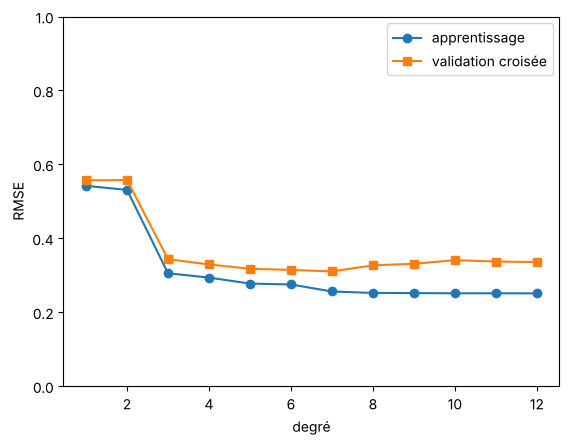

degré choisi : 7


In [6]:
rng = np.random.default_rng(0)
x = rng.uniform(0, 1, 60).reshape(-1, 1)
y = np.sin(2 * np.pi * x).ravel() + rng.normal(0, 0.3, 60)
poly = Pipeline([("poly", PolynomialFeatures(include_bias=False)), ("mco", LinearRegression())])
degres = np.arange(1, 13)
app, val = validation_curve(poly, x, y, param_name="poly__degree", param_range=degres,
                            cv=KFold(5, shuffle=True, random_state=0),
                            scoring="neg_root_mean_squared_error")
plt.plot(degres, -app.mean(axis=1), "o-", label="apprentissage")
plt.plot(degres, -val.mean(axis=1), "s-", label="validation croisée")
plt.xlabel("degré"); plt.ylabel("RMSE"); plt.legend(); plt.ylim(0, 1); plt.show()

rech = GridSearchCV(poly, {"poly__degree": degres}, cv=KFold(5, shuffle=True, random_state=0),
                    scoring="neg_root_mean_squared_error").fit(x, y)
print("degré choisi :", rech.best_params_["poly__degree"])

### 2.2 Moindres carrés ordinaires

`LinearRegression` n'a **aucun hyperparamètre de complexité** : `fit_intercept` (constante, toujours oui), `positive` (coefficients positifs, une contrainte métier), `copy_X` et `n_jobs` (techniques). Il n'y a rien à régler : la validation croisée sert seulement à **estimer** son erreur, pour le comparer aux autres modèles (méthode : `cross_val_score` ou `cross_validate`).

In [7]:
s = cross_val_score(LinearRegression(), Xr_app, yr_app, cv=cv_r,
                    scoring="neg_root_mean_squared_error")
print("Moindres carrés, RMSE de validation croisée :", round(-s.mean(), 2))

Moindres carrés, RMSE de validation croisée : 54.09


### 2.3 Ridge

Minimise $\frac1n\sum_i(y_i-x_i^\top\theta)^2+\lambda\sum_j\theta_j^2$ (chapitre 2). Dans scikit-learn, la pénalité s'appelle `alpha`, avec $\alpha=n\lambda$.

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `alpha` | force de la pénalité : plus grand, coefficients plus petits | **oui**, sur une grille logarithmique |
| `fit_intercept` | constante non pénalisée | non (oui) |
| `positive` | coefficients positifs | non (contrainte métier) |
| `solver`, `max_iter`, `tol` | algorithme de calcul | non (techniques) |

**Méthode** : `RidgeCV(alphas=...)`, qui calcule par défaut une validation croisée *leave-one-out* exacte et très rapide ; ou `RidgeCV(alphas, cv=5)` ; ou `GridSearchCV`. **Standardiser** d'abord : la pénalité dépend de l'échelle des variables.

In [8]:
from sklearn.linear_model import Ridge, RidgeCV
alphas = np.logspace(-3, 3, 50)
ridgecv = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)).fit(Xr_app, yr_app)
print("RidgeCV (leave-one-out) : alpha =", round(ridgecv[-1].alpha_, 3))

pipe = Pipeline([("std", StandardScaler()), ("modele", Ridge())])
rech = GridSearchCV(pipe, {"modele__alpha": alphas}, cv=cv_r,
                    scoring="neg_root_mean_squared_error").fit(Xr_app, yr_app)
bilan(rech, Xr_test, yr_test)

RidgeCV (leave-one-out) : alpha = 25.595


meilleurs hyperparamètres : {'modele__alpha': np.float64(19.306977288832496)}
RMSE de validation croisée : 54.01
RMSE sur le test : 56.3


### 2.4 Lasso

Même critère avec $\lambda\sum_j|\theta_j|$ : certains coefficients deviennent exactement nuls. Dans scikit-learn, `alpha` $=\lambda/2$.

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `alpha` | force de la pénalité : plus grand, plus de coefficients nuls | **oui** |
| `fit_intercept`, `positive` | constante, coefficients positifs | non |
| `selection` (`"cyclic"`, `"random"`), `max_iter`, `tol`, `precompute`, `warm_start` | algorithme de descente par coordonnées | non (techniques) |

**Méthode** : `LassoCV(cv=5)`, qui calcule tout le chemin de régularisation (100 valeurs de `alpha` par défaut) et choisit par validation croisée ; ou `GridSearchCV`.

In [9]:
from sklearn.linear_model import Lasso, LassoCV
lassocv = make_pipeline(StandardScaler(), LassoCV(cv=cv_r, random_state=0)).fit(Xr_app, yr_app)
coef = pd.Series(lassocv[-1].coef_, index=Xr.columns)
print("LassoCV : alpha =", round(lassocv[-1].alpha_, 3), "; variables écartées :",
      list(coef[coef == 0].index))

pipe = Pipeline([("std", StandardScaler()), ("modele", Lasso(max_iter=10000))])
rech = GridSearchCV(pipe, {"modele__alpha": np.logspace(-2, 1, 40)}, cv=cv_r,
                    scoring="neg_root_mean_squared_error").fit(Xr_app, yr_app)
bilan(rech, Xr_test, yr_test)

LassoCV : alpha = 1.142 ; variables écartées : ['s2', 's4']


meilleurs hyperparamètres : {'modele__alpha': np.float64(1.1937766417144369)}
RMSE de validation croisée : 53.89
RMSE sur le test : 56.54


### 2.5 Arbre de régression

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `max_depth` | profondeur maximale | **oui** (le principal) |
| `min_samples_leaf` | effectif minimal d'une feuille | **oui** |
| `min_samples_split` | effectif minimal pour couper un nœud | oui (souvent redondant avec le précédent) |
| `max_leaf_nodes` | nombre maximal de feuilles | oui (autre façon de limiter la taille) |
| `ccp_alpha` | élagage : pénalité par feuille (*cost-complexity pruning*) | **oui** (grille donnée par `cost_complexity_pruning_path`) |
| `min_impurity_decrease` | baisse minimale d'erreur pour couper | parfois |
| `max_features` | variables tirées au hasard à chaque coupure | rarement pour un arbre seul |
| `criterion` | `"squared_error"`, `"absolute_error"`, `"friedman_mse"`, `"poisson"` | parfois (selon la perte voulue) |
| `splitter`, `min_weight_fraction_leaf`, `monotonic_cst`, `random_state` | variantes, contraintes, aléa | non |

**Méthode** : `GridSearchCV`. Pas de standardisation : un arbre ne dépend que de l'ordre des valeurs.

In [10]:
from sklearn.tree import DecisionTreeRegressor
grille = {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 5, 10, 20, 40]}
rech = GridSearchCV(DecisionTreeRegressor(random_state=0), grille, cv=cv_r,
                    scoring="neg_root_mean_squared_error").fit(Xr_app, yr_app)
bilan(rech, Xr_test, yr_test)

# Élagage : la suite des valeurs utiles de ccp_alpha, puis validation croisée
chemin = DecisionTreeRegressor(random_state=0).cost_complexity_pruning_path(Xr_app, yr_app)
ccp = chemin.ccp_alphas[::5]                    # une valeur sur cinq, pour aller vite
rech = GridSearchCV(DecisionTreeRegressor(random_state=0), {"ccp_alpha": ccp}, cv=cv_r,
                    scoring="neg_root_mean_squared_error").fit(Xr_app, yr_app)
print("élagage :", end=" "); bilan(rech, Xr_test, yr_test)
print("feuilles de l'arbre élagué :", rech.best_estimator_.get_n_leaves())

meilleurs hyperparamètres : {'max_depth': 4, 'min_samples_leaf': 20}
RMSE de validation croisée : 60.03
RMSE sur le test : 66.39


élagage : meilleurs hyperparamètres : {'ccp_alpha': np.float64(456.90880723243777)}
RMSE de validation croisée : 66.66
RMSE sur le test : 62.77
feuilles de l'arbre élagué : 3


### 2.6 Forêt aléatoire (régression)

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `max_features` | variables tirées à chaque coupure : décorrèle les arbres (chapitre 3) | **oui** (le plus important) |
| `min_samples_leaf`, `max_depth`, `max_leaf_nodes`, `min_samples_split` | taille des arbres | **oui** (souvent arbres profonds par défaut) |
| `max_samples` | taille de chaque échantillon bootstrap | parfois |
| `n_estimators` | nombre d'arbres | **non** : plus il y en a, mieux c'est ; on augmente jusqu'à ce que l'erreur se stabilise |
| `bootstrap` | tirer avec remise (sinon chaque arbre voit tout) | rarement |
| `criterion`, `ccp_alpha`, `min_impurity_decrease`, `min_weight_fraction_leaf`, `monotonic_cst` | comme l'arbre | rarement |
| `oob_score` | calculer l'erreur *out-of-bag* | outil de validation |
| `n_jobs`, `random_state`, `warm_start`, `verbose` | techniques | non |

**Méthodes** : `RandomizedSearchCV` (grille vite grande) ; l'erreur **out-of-bag** (`oob_score=True`) donne une validation sans découpage, utile pour fixer `n_estimators` ou comparer quelques réglages.

In [11]:
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import randint, uniform, loguniform
distributions = {"max_features": [0.2, 0.33, 0.5, 0.7, 1.0],
                 "min_samples_leaf": randint(1, 30),
                 "max_depth": [None, 4, 6, 8, 12]}
rech = RandomizedSearchCV(RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1),
                          distributions, n_iter=12, cv=cv_r, random_state=0,
                          scoring="neg_root_mean_squared_error").fit(Xr_app, yr_app)
bilan(rech, Xr_test, yr_test)

# Erreur out-of-bag selon le nombre d'arbres : elle se stabilise
for n in [25, 100, 300]:
    f = RandomForestRegressor(n_estimators=n, oob_score=True, random_state=0, n_jobs=-1,
                              **{k: v for k, v in rech.best_params_.items()}).fit(Xr_app, yr_app)
    print(n, "arbres : R2 out-of-bag =", round(f.oob_score_, 3))

meilleurs hyperparamètres : {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 6}
RMSE de validation croisée : 55.51
RMSE sur le test : 58.64
25 arbres : R2 out-of-bag = 0.479


100 arbres : R2 out-of-bag = 0.504


300 arbres : R2 out-of-bag = 0.508


### 2.7 Gradient boosting (régression)

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `learning_rate` | taille de chaque pas de correction | **oui**, avec `n_estimators` |
| `n_estimators` | nombre d'arbres ajoutés | **oui** (ou arrêt précoce) : trop d'arbres sur-apprend |
| `max_depth` (ou `max_leaf_nodes`) | taille de chaque petit arbre (2 à 5) | **oui** |
| `min_samples_leaf`, `min_samples_split` | effectif des feuilles | oui |
| `subsample` | part des individus tirée pour chaque arbre (boosting stochastique) | oui (0,5 à 1) |
| `max_features` | variables tirées à chaque coupure | oui |
| `loss` | `"squared_error"`, `"absolute_error"`, `"huber"`, `"quantile"` (+ `alpha` pour les deux derniers) | selon la perte voulue |
| `n_iter_no_change`, `validation_fraction`, `tol` | **arrêt précoce** : s'arrêter quand l'erreur sur une part de validation ne baisse plus | outil de validation |
| `criterion`, `init`, `ccp_alpha`, `min_impurity_decrease`, `min_weight_fraction_leaf` | variantes | rarement |

**Méthodes** : `RandomizedSearchCV` ; l'arrêt précoce fixe `n_estimators` automatiquement.

In [12]:
from sklearn.ensemble import GradientBoostingRegressor
distributions = {"learning_rate": loguniform(0.01, 0.3), "n_estimators": randint(50, 600),
                 "max_depth": [2, 3, 4], "subsample": uniform(0.5, 0.5),
                 "min_samples_leaf": randint(5, 40)}
rech = RandomizedSearchCV(GradientBoostingRegressor(random_state=0), distributions, n_iter=15,
                          cv=cv_r, random_state=0, n_jobs=-1,
                          scoring="neg_root_mean_squared_error").fit(Xr_app, yr_app)
bilan(rech, Xr_test, yr_test)

# Arrêt précoce : 10 % de l'apprentissage en validation interne, arrêt après 20 tours sans progrès
gb = GradientBoostingRegressor(learning_rate=0.05, n_estimators=2000, max_depth=2,
                               n_iter_no_change=20, validation_fraction=0.1,
                               random_state=0).fit(Xr_app, yr_app)
print("arrêt précoce : arbres utilisés =", gb.n_estimators_)

meilleurs hyperparamètres : {'learning_rate': np.float64(0.016637494603437924), 'max_depth': 2, 'min_samples_leaf': 22, 'n_estimators': 385, 'subsample': np.float64(0.9512992377647023)}
RMSE de validation croisée : 55.85
RMSE sur le test : 59.32
arrêt précoce : arbres utilisés = 133


## 3. Classification

Métrique principale : l'AUC (`scoring="roc_auc"`), insensible au seuil de décision. Pour des classes déséquilibrées, on peut aussi suivre `"recall"`, `"f1"`, `"balanced_accuracy"`, `"average_precision"`.

In [13]:
from sklearn.metrics import roc_auc_score
def bilan_c(rech, X_test, y_test):
    print("meilleurs hyperparamètres :", rech.best_params_)
    print("AUC de validation croisée :", round(rech.best_score_, 4))
    print("AUC sur le test :", round(roc_auc_score(y_test, rech.predict_proba(X_test)[:, 1]), 4))

### 3.1 Le classifieur de référence

`DummyClassifier` n'a pas d'hyperparamètre à régler : `strategy` (`"prior"`, `"most_frequent"`, `"stratified"`, `"uniform"`, `"constant"`) dit seulement quelle règle naïve imiter. Il sert de **référence** : un modèle qui ne fait pas mieux que lui n'apprend rien.

In [14]:
from sklearn.dummy import DummyClassifier
s = cross_validate(DummyClassifier(strategy="most_frequent"), Xc_app, yc_app, cv=cv_c,
                   scoring=["accuracy", "roc_auc"])
print("référence : exactitude", s["test_accuracy"].mean().round(3), "; AUC", s["test_roc_auc"].mean())

référence : exactitude 0.627 ; AUC 0.5


### 3.2 $k$ plus proches voisins

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `n_neighbors` ($k$) | nombre de voisins : petit $k$, forte variance ; grand $k$, fort biais | **oui** (le principal) |
| `weights` | `"uniform"` (vote simple) ou `"distance"` (les plus proches comptent plus) | **oui** |
| `p`, `metric` | distance : `p=2` euclidienne, `p=1` de Manhattan ; autres métriques | oui |
| `metric_params` | paramètres de la métrique | rarement |
| `algorithm`, `leaf_size`, `n_jobs` | rapidité de la recherche des voisins | non (techniques) |

**Méthode** : `GridSearchCV` sur un pipeline **avec standardisation** (les distances dépendent des unités).

In [15]:
pipe = Pipeline([("std", StandardScaler()), ("modele", KNeighborsClassifier())])
grille = {"modele__n_neighbors": [3, 5, 7, 11, 15, 21, 31], "modele__weights": ["uniform", "distance"],
          "modele__p": [1, 2]}
rech = GridSearchCV(pipe, grille, cv=cv_c, scoring="roc_auc", n_jobs=-1).fit(Xc_app, yc_app)
bilan_c(rech, Xc_test, yc_test)

meilleurs hyperparamètres : {'modele__n_neighbors': 11, 'modele__p': 1, 'modele__weights': 'distance'}
AUC de validation croisée : 0.9952
AUC sur le test : 0.9814


### 3.3 Régression logistique

Minimise la perte logistique plus une pénalité : `C` $=1/\lambda$ (petit `C` : forte pénalité).

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `C` | inverse de la force de la pénalité | **oui** (le principal), grille logarithmique |
| type de pénalité : `l1_ratio` (depuis scikit-learn 1.8) ou `penalty` (avant) | `0` / `"l2"` : Ridge ; `1` / `"l1"` : Lasso (sélectionne des variables) ; entre les deux : *elastic net* | **oui** |
| `class_weight` | `None` ou `"balanced"` : donner plus de poids à la classe rare | oui (classes déséquilibrées) |
| `fit_intercept` | constante | non |
| `solver`, `max_iter`, `tol`, `dual`, `intercept_scaling` | algorithme (`"saga"` accepte toutes les pénalités) | non (techniques) |

**Méthodes** : `LogisticRegressionCV` (fait la validation croisée de `C` elle-même) ou `GridSearchCV`. Standardiser d'abord.

In [16]:
from sklearn.linear_model import LogisticRegressionCV
Cs = np.logspace(-3, 2, 8)
opts = dict(l1_ratios=(0,), use_legacy_attributes=False) if NOUVEAU else {}
lrcv = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=Cs, cv=cv_c, scoring="roc_auc",
                                                            max_iter=5000, **opts))
lrcv.fit(Xc_app, yc_app)
print("LogisticRegressionCV : C =", np.ravel(lrcv[-1].C_)[0].round(4))

pipe = Pipeline([("std", StandardScaler()),
                 ("modele", LogisticRegression(solver="saga", max_iter=3000, tol=1e-3))])
if NOUVEAU:        # scikit-learn >= 1.8 : le type de pénalité se règle par l1_ratio
    grille = {"modele__C": Cs, "modele__l1_ratio": [0, 0.5, 1],
              "modele__class_weight": [None, "balanced"]}
else:              # versions antérieures : penalty
    grille = [{"modele__penalty": ["l2", "l1"], "modele__C": Cs,
               "modele__class_weight": [None, "balanced"]},
              {"modele__penalty": ["elasticnet"], "modele__l1_ratio": [0.5], "modele__C": Cs,
               "modele__class_weight": [None, "balanced"]}]
rech = GridSearchCV(pipe, grille, cv=cv_c, scoring="roc_auc", n_jobs=-1).fit(Xc_app, yc_app)
bilan_c(rech, Xc_test, yc_test)

LogisticRegressionCV : C = 0.1389


meilleurs hyperparamètres : {'modele__C': np.float64(0.13894954943731375), 'modele__class_weight': 'balanced', 'modele__l1_ratio': 1}
AUC de validation croisée : 0.9962
AUC sur le test : 0.9807


### 3.4 Arbre de classification

Mêmes hyperparamètres que l'arbre de régression (section 2.5), avec deux différences :

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `criterion` | impureté : `"gini"` (cours), `"entropy"` ou `"log_loss"` | parfois |
| `class_weight` | `None` ou `"balanced"` | oui (classes déséquilibrées) |
| `max_depth`, `min_samples_leaf`, `min_samples_split`, `max_leaf_nodes`, `ccp_alpha`, `min_impurity_decrease`, `max_features` | comme en régression | **oui** pour les trois premiers et `ccp_alpha` |

**Méthode** : `GridSearchCV`.

In [17]:
from sklearn.tree import DecisionTreeClassifier
grille = {"max_depth": [2, 3, 4, 5, 6, None], "min_samples_leaf": [1, 5, 10, 20],
          "criterion": ["gini", "entropy"], "class_weight": [None, "balanced"]}
rech = GridSearchCV(DecisionTreeClassifier(random_state=0), grille, cv=cv_c,
                    scoring="roc_auc", n_jobs=-1).fit(Xc_app, yc_app)
bilan_c(rech, Xc_test, yc_test)

meilleurs hyperparamètres : {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5}
AUC de validation croisée : 0.9764
AUC sur le test : 0.972


### 3.5 Bagging

Moyenne de $B$ modèles (des arbres par défaut) appris sur des échantillons bootstrap.

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `estimator` | le modèle de base (arbre par défaut) | choix du modèle |
| `estimator__max_depth`, `estimator__min_samples_leaf`, … | hyperparamètres du modèle de base, préfixés par `estimator__` | **oui** |
| `max_samples` | taille de chaque échantillon (part ou nombre) | **oui** |
| `max_features` | part des variables vue par chaque modèle | **oui** |
| `bootstrap`, `bootstrap_features` | tirage avec remise des individus, des variables | parfois |
| `n_estimators` | nombre de modèles : plus, c'est mieux (jusqu'à stabilité) | non |
| `oob_score` | erreur *out-of-bag* | outil de validation |
| `n_jobs`, `random_state`, `warm_start`, `verbose` | techniques | non |

**Méthodes** : `GridSearchCV` ; l'exactitude *out-of-bag* (`oob_score_`) en contrôle.

In [18]:
from sklearn.ensemble import BaggingClassifier
bag = BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=100,
                        random_state=0, n_jobs=-1)
grille = {"estimator__max_depth": [3, 6, None], "max_samples": [0.5, 0.8, 1.0],
          "max_features": [0.5, 1.0]}
rech = GridSearchCV(bag, grille, cv=cv_c, scoring="roc_auc").fit(Xc_app, yc_app)
bilan_c(rech, Xc_test, yc_test)
oob = BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=200, oob_score=True,
                        random_state=0, n_jobs=-1).fit(Xc_app, yc_app)
print("exactitude out-of-bag :", round(oob.oob_score_, 3))

meilleurs hyperparamètres : {'estimator__max_depth': None, 'max_features': 0.5, 'max_samples': 1.0}
AUC de validation croisée : 0.9962
AUC sur le test : 0.9782


exactitude out-of-bag : 0.962


### 3.6 Forêt aléatoire (classification)

Mêmes hyperparamètres que la forêt de régression (section 2.6), avec `criterion` (`"gini"`, `"entropy"`, `"log_loss"`) et `class_weight` (`None`, `"balanced"`, `"balanced_subsample"`). Les plus importants : `max_features` (par défaut $\sqrt{d}$ en classification), `min_samples_leaf`, `max_depth`, `class_weight`. `n_estimators` ne se règle pas : on en met assez.

**Méthodes** : `RandomizedSearchCV` ou `GridSearchCV` ; `oob_score=True`.

In [19]:
from sklearn.ensemble import RandomForestClassifier
distributions = {"max_features": ["sqrt", "log2", 0.2, 0.4, 0.6],
                 "min_samples_leaf": randint(1, 20), "max_depth": [None, 4, 8, 12],
                 "class_weight": [None, "balanced", "balanced_subsample"]}
rech = RandomizedSearchCV(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                          distributions, n_iter=12, cv=cv_c, scoring="roc_auc",
                          random_state=0).fit(Xc_app, yc_app)
bilan_c(rech, Xc_test, yc_test)

meilleurs hyperparamètres : {'class_weight': None, 'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 1}
AUC de validation croisée : 0.9955
AUC sur le test : 0.9782


### 3.7 AdaBoost

Ajoute des arbres très simples (souches) en donnant plus de poids aux individus mal classés (chapitre 3).

| hyperparamètre | rôle | par validation croisée ? |
|---|---|---|
| `n_estimators` | nombre de tours | **oui**, avec `learning_rate` |
| `learning_rate` | réduit le poids de vote de chaque tour | **oui** |
| `estimator` et `estimator__max_depth` | modèle de base : souche (profondeur 1) par défaut, ou arbre de profondeur 2-3 | **oui** |
| `random_state` | aléa | non |

(Le paramètre `algorithm` des anciennes versions a été retiré.) **Méthode** : `GridSearchCV`.

In [20]:
from sklearn.ensemble import AdaBoostClassifier
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), random_state=0)
grille = {"n_estimators": [50, 100, 200], "learning_rate": [0.1, 0.5, 1.0],
          "estimator__max_depth": [1, 2]}
rech = GridSearchCV(ada, grille, cv=cv_c, scoring="roc_auc", n_jobs=-1).fit(Xc_app, yc_app)
bilan_c(rech, Xc_test, yc_test)

meilleurs hyperparamètres : {'estimator__max_depth': 2, 'learning_rate': 1.0, 'n_estimators': 50}
AUC de validation croisée : 0.9943
AUC sur le test : 0.9872


### 3.8 Gradient boosting (classification)

Mêmes hyperparamètres que le gradient boosting de régression (section 2.7) ; `loss` vaut `"log_loss"` (par défaut) ou `"exponential"` (qui redonne AdaBoost). À régler : `learning_rate` et `n_estimators` ensemble (ou arrêt précoce), `max_depth`, `subsample`, `min_samples_leaf`, `max_features`.

**Méthodes** : `RandomizedSearchCV` ; arrêt précoce (`n_iter_no_change`).

In [21]:
from sklearn.ensemble import GradientBoostingClassifier
distributions = {"learning_rate": loguniform(0.01, 0.3), "n_estimators": randint(50, 500),
                 "max_depth": [1, 2, 3, 4], "subsample": uniform(0.5, 0.5),
                 "min_samples_leaf": randint(1, 30), "max_features": [None, "sqrt", 0.5]}
rech = RandomizedSearchCV(GradientBoostingClassifier(random_state=0), distributions, n_iter=15,
                          cv=cv_c, scoring="roc_auc", random_state=0, n_jobs=-1).fit(Xc_app, yc_app)
bilan_c(rech, Xc_test, yc_test)

meilleurs hyperparamètres : {'learning_rate': np.float64(0.2651225974297431), 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 7, 'n_estimators': 89, 'subsample': np.float64(0.7644474598764522)}
AUC de validation croisée : 0.9953
AUC sur le test : 0.9889


### 3.9 Le seuil de décision, un hyperparamètre comme les autres

Un classifieur prédit la classe 1 quand sa probabilité dépasse un seuil, $\frac12$ par défaut. Quand les erreurs n'ont pas le même coût (chapitre 1), ou pour viser un bon rappel, on choisit le seuil **par validation croisée**, jamais sur le test. **Méthode** : `TunedThresholdClassifierCV` (scikit-learn 1.5 et plus), avec la métrique à maximiser.

In [22]:
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.metrics import balanced_accuracy_score, recall_score
modele = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))
ajuste = TunedThresholdClassifierCV(modele, scoring="balanced_accuracy", cv=cv_c).fit(Xc_app, yc_app)
print("seuil choisi :", round(ajuste.best_threshold_, 3))
print("exactitude équilibrée sur le test : seuil 0,5 =",
      round(balanced_accuracy_score(yc_test, modele.fit(Xc_app, yc_app).predict(Xc_test)), 3),
      "; seuil choisi =", round(balanced_accuracy_score(yc_test, ajuste.predict(Xc_test)), 3))

seuil choisi : 0.586
exactitude équilibrée sur le test : seuil 0,5 = 0.947 ; seuil choisi = 0.949


## 4. Non supervisé

Sans variable à prédire, il n'y a pas d'erreur de prédiction à valider : la validation croisée « classique » ne s'applique pas directement. On choisit les hyperparamètres avec des **critères internes** (inertie, silhouette, éboulis) et l'**interprétation**. Deux exceptions : l'ACP a une vraisemblance qu'on peut valider, et un modèle non supervisé placé dans un pipeline supervisé se règle par `GridSearchCV` comme le reste.

### 4.1 Analyse en composantes principales

| hyperparamètre | rôle | comment le choisir |
|---|---|---|
| `n_components` | nombre d'axes gardés (entier, ou part d'inertie comme `0.8`) | éboulis, règle de Kaiser (valeur propre $>1$ en ACP normée), $70$-$80\,\%$ d'inertie ; **ou validation croisée** de la vraisemblance ; **ou** `GridSearchCV` dans un pipeline supervisé |
| `whiten` | rend les composantes de variance 1 | selon l'usage aval |
| `svd_solver`, `tol`, `iterated_power`, `random_state` | calcul | non (techniques) |

In [23]:
from sklearn.decomposition import PCA
Zc = StandardScaler().fit_transform(Xc_app)          # ACP normée des 30 variables
acp = PCA().fit(Zc)
print("valeurs propres > 1 (Kaiser) :", (acp.explained_variance_ > 1).sum(), "axes")
print("axes pour 80 % d'inertie :", np.searchsorted(np.cumsum(acp.explained_variance_ratio_), 0.8) + 1)

# Validation croisée de la vraisemblance de l'ACP (PCA.score = log-vraisemblance moyenne)
for q in [2, 5, 7, 10, 15, 20]:
    print(q, "axes : log-vraisemblance de validation =",
          cross_val_score(PCA(n_components=q), Zc, cv=KFold(5, shuffle=True, random_state=0)).mean().round(2))

# ACP dans un pipeline supervisé : le nombre d'axes se règle par GridSearchCV
pipe = Pipeline([("std", StandardScaler()), ("acp", PCA()),
                 ("modele", LogisticRegression(max_iter=5000))])
rech = GridSearchCV(pipe, {"acp__n_components": [2, 3, 5, 8, 12, 20]}, cv=cv_c,
                    scoring="roc_auc").fit(Xc_app, yc_app)
bilan_c(rech, Xc_test, yc_test)

valeurs propres > 1 (Kaiser) : 6 axes
axes pour 80 % d'inertie : 5
2 axes : log-vraisemblance de validation = -32.39
5 axes : log-vraisemblance de validation = -26.39
7 axes : log-vraisemblance de validation = -23.33
10 axes : log-vraisemblance de validation = -20.12
15 axes : log-vraisemblance de validation = -17.18
20 axes : log-vraisemblance de validation = -18.57


meilleurs hyperparamètres : {'acp__n_components': 8}
AUC de validation croisée : 0.9958
AUC sur le test : 0.9948


### 4.2 k-means

| hyperparamètre | rôle | comment le choisir |
|---|---|---|
| `n_clusters` ($k$) | nombre de classes | **coude** de l'inertie intra-classe, **silhouette** (`silhouette_score`), interprétation |
| `init` | centres de départ : `"k-means++"`, `"random"`, ou un tableau de centres (section 6) | `"k-means++"` par défaut |
| `n_init` | nombre de départs ; on garde la meilleure inertie | assez grand (10 et plus) |
| `max_iter`, `tol`, `algorithm` (`"lloyd"`, `"elkan"`), `random_state` | calcul | non |

**Méthode** : une boucle sur $k$ avec `inertia_` et `silhouette_score`. La silhouette d'un individu compare la distance moyenne à sa classe et à la classe voisine ; elle va de $-1$ à $1$ ; plus la moyenne est grande, mieux les classes sont séparées.

,inertie intra,silhouette
k,,
2,6691.593,0.395
3,5546.732,0.354
4,5003.215,0.213
5,4495.184,0.212
6,4108.577,0.216
7,3783.091,0.224
8,3490.622,0.203


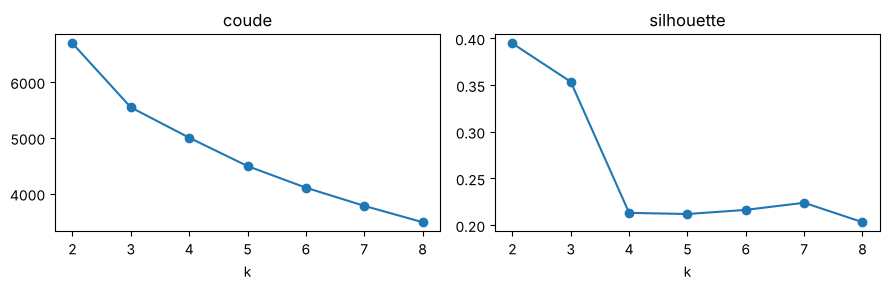

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
coord = PCA(n_components=5).fit_transform(Zc)
res = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(coord)
    res.append((k, km.inertia_, silhouette_score(coord, km.labels_)))
res = pd.DataFrame(res, columns=["k", "inertie intra", "silhouette"]).set_index("k")
display(res.round(3))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
res["inertie intra"].plot(ax=ax[0], marker="o", title="coude"); res["silhouette"].plot(ax=ax[1], marker="o", title="silhouette")
plt.tight_layout(); plt.show()

### 4.3 Classification ascendante hiérarchique

| hyperparamètre | rôle | comment le choisir |
|---|---|---|
| `linkage` | critère d'agrégation : `"ward"` (cours), `"complete"`, `"average"`, `"single"` | Ward pour des classes compactes (variables quantitatives) |
| `n_clusters` ou `distance_threshold` | où couper l'arbre | **dendrogramme** (grand saut de hauteur), **silhouette** |
| `metric` | distance (euclidienne pour Ward) | selon les données |
| `connectivity`, `compute_full_tree`, `compute_distances` | contraintes, calcul | non |

**Méthode** : `scipy.cluster.hierarchy.linkage` et `dendrogram` pour voir l'arbre ; une boucle sur le nombre de classes avec `silhouette_score`. Attention : une silhouette élevée avec les liens `"complete"` ou `"average"` vient souvent d'une partition déséquilibrée (une très grande classe et quelques individus isolés) ; regarder aussi les effectifs des classes.

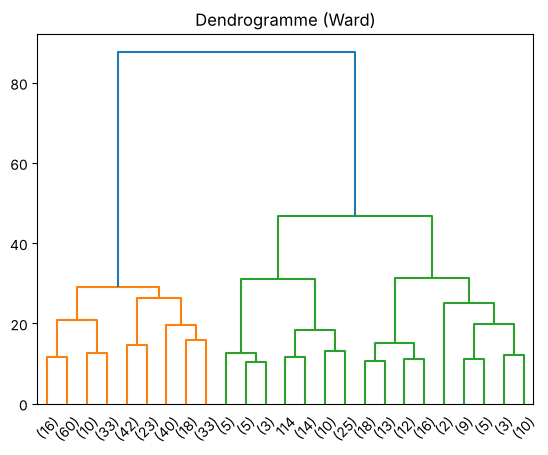

ward      silhouette pour k = 2..6 : [0.37  0.346 0.32  0.317 0.161]
complete  silhouette pour k = 2..6 : [0.66  0.314 0.289 0.263 0.252]
average   silhouette pour k = 2..6 : [0.66  0.487 0.455 0.332 0.261]


In [25]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import AgglomerativeClustering
arbre = linkage(coord, method="ward")
dendrogram(arbre, truncate_mode="lastp", p=25); plt.title("Dendrogramme (Ward)"); plt.show()
for methode in ["ward", "complete", "average"]:
    sil = [silhouette_score(coord, AgglomerativeClustering(n_clusters=k, linkage=methode).fit_predict(coord))
           for k in range(2, 7)]
    print(f"{methode:9s} silhouette pour k = 2..6 :", np.round(sil, 3))

### 4.4 Forêt d'isolement

| hyperparamètre | rôle | comment le choisir |
|---|---|---|
| `contamination` | part d'individus déclarés atypiques : c'est un **seuil de décision**, pas un réglage du score | selon l'usage (combien de cas peut-on vérifier ?) |
| `n_estimators` | nombre d'arbres | assez (100 et plus) |
| `max_samples` | taille de l'échantillon de chaque arbre (256 par défaut) | parfois |
| `max_features`, `bootstrap` | variables et tirage | rarement |

Sans étiquettes, pas de validation croisée : on choisit `contamination` selon l'usage. **Si l'on connaît quelques vraies anomalies**, on peut régler les autres hyperparamètres par `GridSearchCV` avec une métrique qui compare le score d'anomalie aux étiquettes (ici, les tumeurs malignes, minoritaires, jouent le rôle d'anomalies).

In [26]:
from sklearn.ensemble import IsolationForest
anomalie = (yc_app == 0).astype(int)                # 1 = maligne, considérée comme atypique
def auc_anomalie(modele, X, y):                     # plus le score est bas, plus c'est atypique
    return roc_auc_score(y, -modele.decision_function(X))
rech = GridSearchCV(IsolationForest(random_state=0),
                    {"n_estimators": [100, 300], "max_samples": [64, 128, 256],
                     "max_features": [0.5, 1.0]},
                    cv=cv_c, scoring=auc_anomalie).fit(Zc, anomalie)
print("meilleur :", rech.best_params_, "AUC :", round(rech.best_score_, 3))
for c in [0.05, 0.1, 0.2]:
    f = IsolationForest(contamination=c, random_state=0).fit(Zc)
    print(f"contamination {c} : {(f.predict(Zc) == -1).mean():.1%} déclarés atypiques")

meilleur : {'max_features': 0.5, 'max_samples': 64, 'n_estimators': 300} AUC : 0.833
contamination 0.05 : 5.2% déclarés atypiques


contamination 0.1 : 10.1% déclarés atypiques
contamination 0.2 : 20.0% déclarés atypiques


## 5. Récapitulatif

| modèle | classe scikit-learn | hyperparamètres à choisir par validation croisée | méthode de validation croisée |
|---|---|---|---|
| polynomiale | `PolynomialFeatures` + `LinearRegression` | `degree` | `validation_curve`, `GridSearchCV` |
| moindres carrés | `LinearRegression` | aucun | `cross_val_score` (estimation seulement) |
| Ridge | `Ridge` | `alpha` | `RidgeCV`, `GridSearchCV` |
| Lasso | `Lasso` | `alpha` | `LassoCV`, `GridSearchCV` |
| arbre | `DecisionTreeRegressor`, `DecisionTreeClassifier` | `max_depth`, `min_samples_leaf`, `min_samples_split`, `max_leaf_nodes`, `ccp_alpha` (+ `criterion`, `class_weight`) | `GridSearchCV` (+ `cost_complexity_pruning_path`) |
| forêt aléatoire | `RandomForestRegressor`, `RandomForestClassifier` | `max_features`, `min_samples_leaf`, `max_depth`, `max_samples` (+ `class_weight`) ; `n_estimators` : assez | `RandomizedSearchCV`, `oob_score` |
| gradient boosting | `GradientBoostingRegressor`, `GradientBoostingClassifier` | `learning_rate` et `n_estimators`, `max_depth`, `subsample`, `min_samples_leaf`, `max_features` | `RandomizedSearchCV`, arrêt précoce (`n_iter_no_change`) |
| référence | `DummyClassifier` | aucun | `cross_validate` (estimation) |
| $k$ plus proches voisins | `KNeighborsClassifier` | `n_neighbors`, `weights`, `p` / `metric` | `GridSearchCV` (avec standardisation) |
| régression logistique | `LogisticRegression` | `C`, type de pénalité (`l1_ratio` ou `penalty`), `class_weight` | `LogisticRegressionCV`, `GridSearchCV` |
| bagging | `BaggingClassifier` | `estimator__…`, `max_samples`, `max_features` | `GridSearchCV`, `oob_score` |
| AdaBoost | `AdaBoostClassifier` | `n_estimators`, `learning_rate`, `estimator__max_depth` | `GridSearchCV` |
| seuil de décision | tout classifieur | le seuil | `TunedThresholdClassifierCV` |
| ACP | `PCA` | `n_components` | éboulis, Kaiser ; `cross_val_score(PCA(q))` ; `GridSearchCV` dans un pipeline |
| k-means | `KMeans` | `n_clusters` | coude, `silhouette_score` |
| CAH | `AgglomerativeClustering`, `scipy...linkage` | `linkage`, `n_clusters` | dendrogramme, `silhouette_score` |
| forêt d'isolement | `IsolationForest` | `contamination` (usage), `max_samples`, `max_features` | pas de validation sans étiquettes ; `GridSearchCV` avec un score si quelques anomalies sont connues |

**Pour le projet.** Tout se fait sur l'échantillon d'apprentissage, dans un pipeline ; le test ne sert qu'une fois, à la fin. Données DHS : plis stratifiés (`StratifiedKFold`), éventuellement par mère ou par grappe (`GroupKFold`) ; métrique adaptée au déséquilibre des classes (`roc_auc`, `recall`, `f1`).

## 6. Consolidation k-means après CAH

La CAH donne une partition à partir d'un arbre, mais un individu affecté à une classe n'est jamais réaffecté ensuite, même s'il est plus près du centre d'une autre classe. Le k-means, lui, dépend de ses centres de départ. On combine les deux :

1. CAH de Ward, choix du nombre de classes $k$ sur le dendrogramme ;
2. calcul des **centres** (moyennes) des $k$ classes de la CAH ;
3. **k-means partant de ces centres** : `KMeans(n_clusters=k, init=centres, n_init=1)`. Chaque individu rejoint le centre le plus proche, les centres sont recalculés, et ainsi de suite.

L'inertie intra-classe ne peut que baisser (chapitre 4). Exemple sur les données `wine` (178 vins, 13 mesures chimiques, fournies avec scikit-learn), après ACP normée.

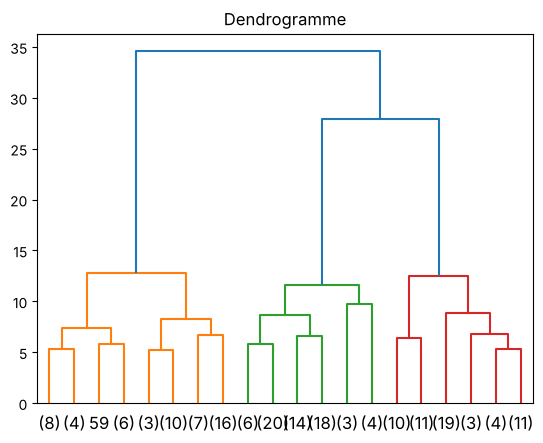

inertie intra : CAH = 865.6 ; après consolidation = 826.3
silhouette : CAH = 0.347 ; après consolidation = 0.368
individus qui ont changé de classe : 9


consolidée,1,2,3
CAH,,,
1,49,0,6
2,0,64,1
3,2,0,56


In [27]:
from sklearn.datasets import load_wine
vins = load_wine(as_frame=True).frame.drop(columns="target")
Z = StandardScaler().fit_transform(vins)
coord = PCA(n_components=5).fit_transform(Z)            # on classe sur les 5 premiers axes

# 1. CAH de Ward et choix de k
arbre = linkage(coord, method="ward")
dendrogram(arbre, truncate_mode="lastp", p=20); plt.title("Dendrogramme"); plt.show()
k = 3
classes_cah = fcluster(arbre, t=k, criterion="maxclust")         # classes 1..k

# 2. Centres des classes de la CAH
centres = np.vstack([coord[classes_cah == c].mean(axis=0) for c in range(1, k + 1)])

# 3. k-means partant de ces centres : la consolidation
km = KMeans(n_clusters=k, init=centres, n_init=1).fit(coord)
classes_km = km.labels_ + 1          # même numérotation que la CAH : le centre c donne la classe c

def inertie_intra(X, classes):
    return sum(((X[classes == c] - X[classes == c].mean(axis=0)) ** 2).sum() for c in np.unique(classes))
print("inertie intra : CAH =", round(inertie_intra(coord, classes_cah), 1),
      "; après consolidation =", round(km.inertia_, 1))
print("silhouette : CAH =", round(silhouette_score(coord, classes_cah), 3),
      "; après consolidation =", round(silhouette_score(coord, classes_km), 3))
print("individus qui ont changé de classe :", (classes_cah != classes_km).sum())
display(pd.crosstab(pd.Series(classes_cah, name="CAH"), pd.Series(classes_km, name="consolidée")))

**Variante** avec `AgglomerativeClustering` à la place de `scipy` : les classes vont de 0 à $k-1$.

In [28]:
cah = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(coord)
centres = np.vstack([coord[cah.labels_ == c].mean(axis=0) for c in range(k)])
km = KMeans(n_clusters=k, init=centres, n_init=1).fit(coord)

# Décrire les classes consolidées avec les variables d'origine
profil = vins.groupby(km.labels_ + 1).mean().round(2)
profil.insert(0, "effectif", np.bincount(km.labels_))
display(profil.T)

,1,2,3
effectif,51.00,63.00,64.00
alcohol,13.13,12.25,13.63
malic_acid,3.31,1.92,1.97
ash,2.42,2.24,2.45
alcalinity_of_ash,21.24,20.20,17.41
magnesium,98.67,91.13,109.08
total_phenols,1.68,2.26,2.82
flavanoids,0.82,2.07,2.96
nonflavanoid_phenols,0.45,0.36,0.29
proanthocyanins,1.15,1.59,1.94
